In [ ]:
from google.colab import files
uploaded=files.upload()

Saving Netflix.csv to Netflix.csv


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn. metrics import mean_absolute_error, mean_squared_error,r2_score
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import BernoulliNB
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import seaborn as sns
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import spacy
nlp=spacy.load("en_core_web_sm")
from spacy.lang.en.stop_words import STOP_WORDS
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import plot_tree
from sklearn.svm import SVC
from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import linkage
from sklearn.cluster import AgglomerativeClustering
from sklearn.cluster import KMeans
from sklearn.cluster import BisectingKMeans
from sklearn.semi_supervised import SelfTrainingClassifier
from sklearn.metrics.pairwise import cosine_similarity

In [ ]:
df=pd.read_csv("Netflix.csv")
print(df)

      Unnamed: 0                          title    year            kind  \
0              0                Dinosaur Planet  2003.0  tv mini series   
1              1                      Character  2021.0           movie   
2              2              Get Up and Dance!  1994.0     video movie   
3              3  The Rise and Fall of El Chapo  2016.0        tv movie   
4              4                    Sick - IMDb     NaN             NaN   
...          ...                            ...     ...             ...   
9821        9821            All Monsters Attack  1969.0           movie   
9822        9822                   Fidel Castro  2005.0         episode   
9823        9823                          Epoch  2001.0        tv movie   
9824        9824                    The Company  2003.0           movie   
9825        9825                       Predator  1987.0           movie   

                                              genre  rating      vote  \
0            ['Documentary

In [ ]:
print("\nColumns:")
print(df.columns)


Columns:
Index(['Unnamed: 0', 'title', 'year', 'kind', 'genre', 'rating', 'vote',
       'country', 'language', 'cast', 'director', 'composer', 'writer',
       'runtime'],
      dtype='object')


In [ ]:
print("Shape:")
print(df.shape)

print("\nData Types:")
print(df.dtypes)

print("\nInformation:")
df.info()

Shape:
(9826, 14)

Data Types:
Unnamed: 0      int64
title          object
year          float64
kind           object
genre          object
rating        float64
vote          float64
country        object
language       object
cast           object
director       object
composer       object
writer         object
runtime       float64
dtype: object

Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9826 entries, 0 to 9825
Data columns (total 14 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  9826 non-null   int64  
 1   title       9825 non-null   object 
 2   year        9756 non-null   float64
 3   kind        9788 non-null   object 
 4   genre       9733 non-null   object 
 5   rating      8949 non-null   float64
 6   vote        8949 non-null   float64
 7   country     9161 non-null   object 
 8   language    9033 non-null   object 
 9   cast        9482 non-null   object 
 10  director    7966 non-null   o

In [ ]:
print("\nMissing Values:")
print(df.isnull().sum())


Missing Values:
Unnamed: 0       0
title            1
year            70
kind            38
genre           93
rating         877
vote           877
country        665
language       793
cast           344
director      1860
composer      3622
writer        1656
runtime       1056
dtype: int64


In [ ]:
print("\nDuplicate Records:")
print(df.duplicated().sum())


Duplicate Records:
0


In [ ]:
print("\nUnique Values:")
print(df.nunique())


Unique Values:
Unnamed: 0    9826
title         9214
year           109
kind             8
genre         1557
rating          84
vote          5036
country        728
language       768
cast          8850
director      5018
composer      3296
writer        7051
runtime        317
dtype: int64


In [ ]:
if 'Unnamed: 0' in df.columns:
    df = df.drop(columns=['Unnamed: 0'])

In [ ]:
numeric_cols = [
    'year',
    'rating',
    'vote',
    'runtime'
]

In [ ]:
for col in numeric_cols:
    df[col] = pd.to_numeric(
        df[col],
        errors='coerce'
    )

In [ ]:
for col in numeric_cols:
    df[col] = df[col].fillna(
        df[col].median()
    )

print("\nMissing values after preprocessing:")
print(df[numeric_cols].isnull().sum())


Missing values after preprocessing:
year       0
rating     0
vote       0
runtime    0
dtype: int64


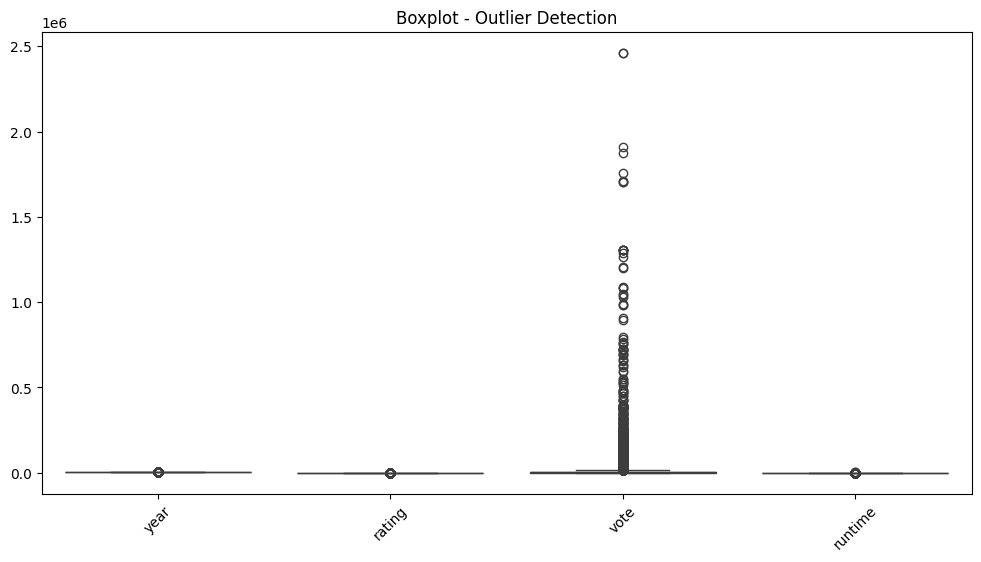

In [ ]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df
)
plt.title("Boxplot - Outlier Detection")
plt.xticks(rotation=45)
plt.show()

In [ ]:
def remove_outliers(data, column):

    Q1 = data[column].quantile(0.25)

    Q3 = data[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR

    upper_bound = Q3 + 1.5 * IQR

    data = data[
        (data[column] >= lower_bound) &
        (data[column] <= upper_bound)
    ]

    return data

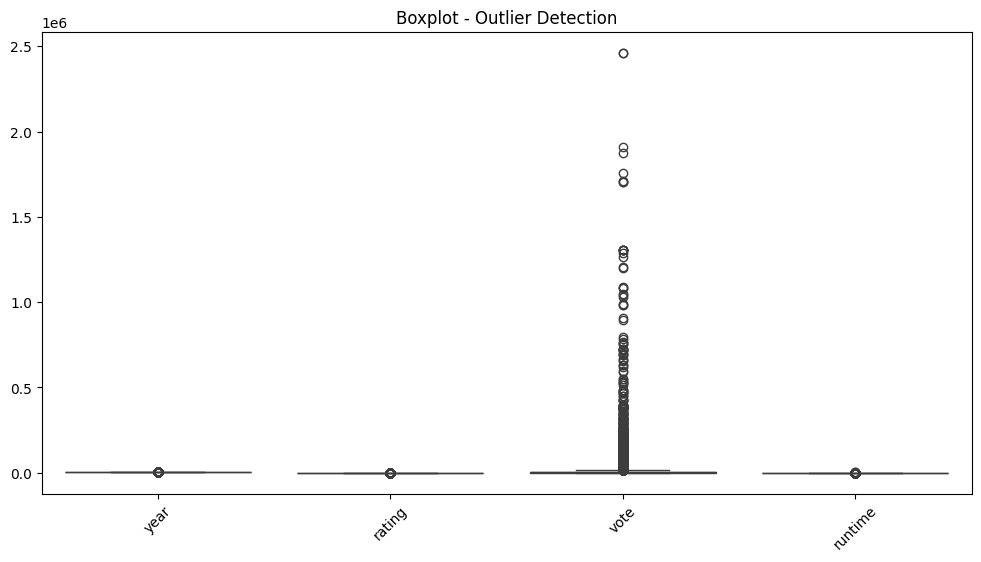

In [ ]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df
)
plt.title("Boxplot - Outlier Detection")
plt.xticks(rotation=45)
plt.show()

In [ ]:
print(df.shape)

(9826, 13)


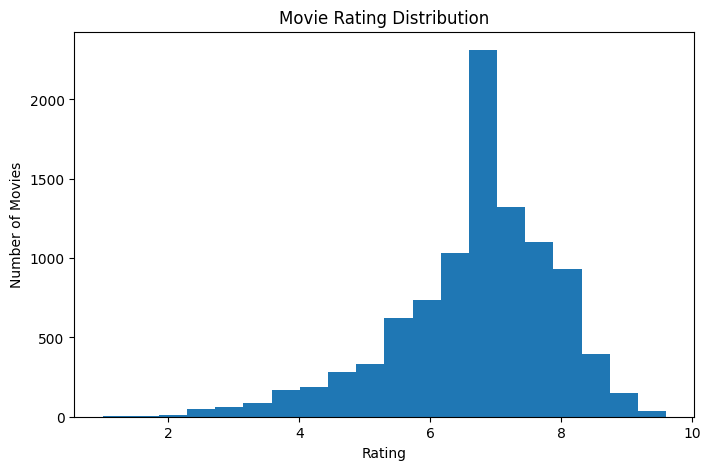

In [ ]:
plt.figure(figsize=(8,5))

plt.hist(
    df['rating'],
    bins=20
)

plt.xlabel("Rating")
plt.ylabel("Number of Movies")

plt.title("Movie Rating Distribution")

plt.show()

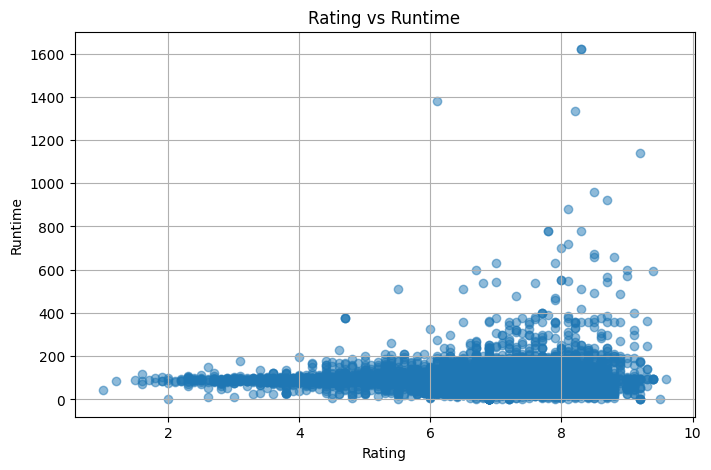

In [ ]:
plt.figure(figsize=(8,5))

plt.scatter(
    df['rating'],
    df['runtime'],
    alpha=0.5
)

plt.xlabel("Rating")
plt.ylabel("Runtime")

plt.title("Rating vs Runtime")

plt.grid()

plt.show()

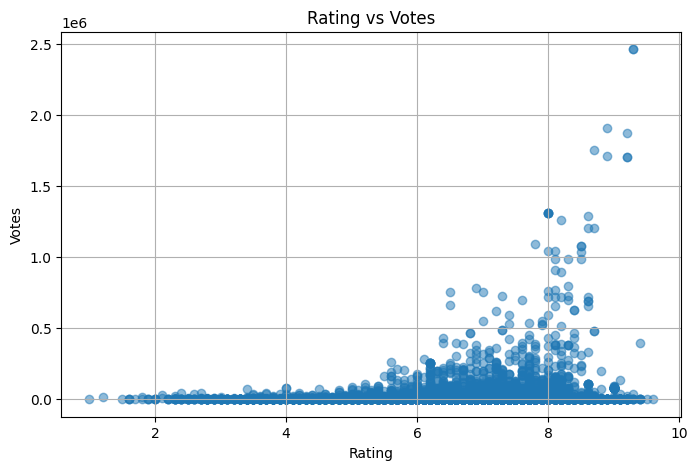

In [ ]:
plt.figure(figsize=(8,5))

plt.scatter(
    df['rating'],
    df['vote'],
    alpha=0.5
)

plt.xlabel("Rating")
plt.ylabel("Votes")

plt.title("Rating vs Votes")

plt.grid()

plt.show()

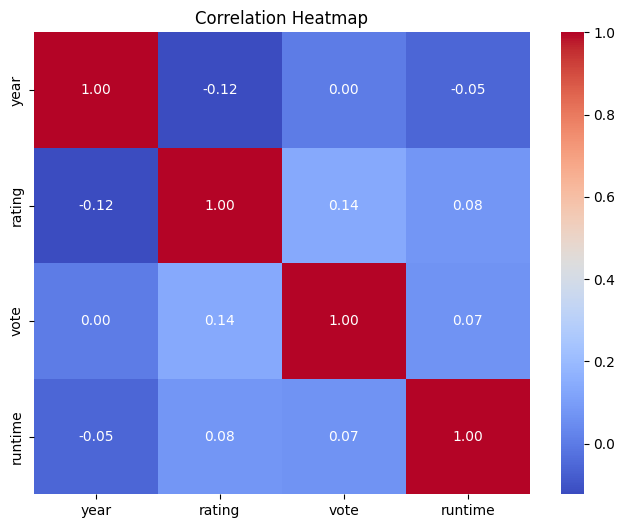

In [ ]:
plt.figure(figsize=(8,6))

correlation = df[
    numeric_cols
].corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Heatmap")

plt.show()

In [ ]:
X = df[
    [
        'year',
        'rating',
        'vote',
        'runtime'
    ]
]

print(X)

        year  rating      vote  runtime
0     2003.0     7.7     474.0     50.0
1     2021.0     8.3      46.0    125.0
2     1994.0     8.1      18.0     54.0
3     2016.0     6.9      42.0     85.0
4     1999.0     6.9    1535.0     94.0
...      ...     ...       ...      ...
9821  1969.0     3.9    4384.0     69.0
9822  2005.0     6.4      44.0     94.0
9823  2001.0     4.9    2376.0     96.0
9824  2003.0     6.3    6501.0    112.0
9825  1987.0     7.8  386850.0    107.0

[9826 rows x 4 columns]


In [ ]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print(X_scaled[:5])

[[ 0.50832434  0.81419286 -0.20256747 -0.79157839]
 [ 1.6201043   1.30281301 -0.20713359  0.45481864]
 [-0.04756564  1.13993962 -0.20743231 -0.72510388]
 [ 1.31127653  0.16269934 -0.20717626 -0.20992644]
 [ 0.26126213  0.16269934 -0.19124818 -0.0603588 ]]


In [ ]:
kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

labels = kmeans.fit_predict(
    X_scaled
)

df['Cluster'] = labels

print(
    df[
        [
            'title',
            'rating',
            'vote',
            'runtime',
            'Cluster'
        ]
    ]
)

                              title  rating      vote  runtime  Cluster
0                   Dinosaur Planet     7.7     474.0     50.0        0
1                         Character     8.3      46.0    125.0        0
2                 Get Up and Dance!     8.1      18.0     54.0        0
3     The Rise and Fall of El Chapo     6.9      42.0     85.0        0
4                       Sick - IMDb     6.9    1535.0     94.0        0
...                             ...     ...       ...      ...      ...
9821            All Monsters Attack     3.9    4384.0     69.0        1
9822                   Fidel Castro     6.4      44.0     94.0        0
9823                          Epoch     4.9    2376.0     96.0        0
9824                    The Company     6.3    6501.0    112.0        0
9825                       Predator     7.8  386850.0    107.0        1

[9826 rows x 5 columns]


In [ ]:
centroids = kmeans.cluster_centers_
print("Scaled Centroids:")
print(centroids)

Scaled Centroids:
[[ 0.38857237 -0.12364527 -0.08960568 -0.10150035]
 [-1.49227105  0.47484657  0.34412111  0.38980133]]


In [ ]:
centroids_original = scaler.inverse_transform(
    kmeans.cluster_centers_
)

centroid_df = pd.DataFrame(
    centroids_original,
    columns=[
        'year',
        'rating',
        'vote',
        'runtime'
    ]
)

print("\nOriginal Centroids:")
print(centroid_df)


Original Centroids:
          year    rating          vote     runtime
0  2001.061185  6.548384  11062.340688   91.524371
1  1970.609852  7.283300  51717.210837  121.087685


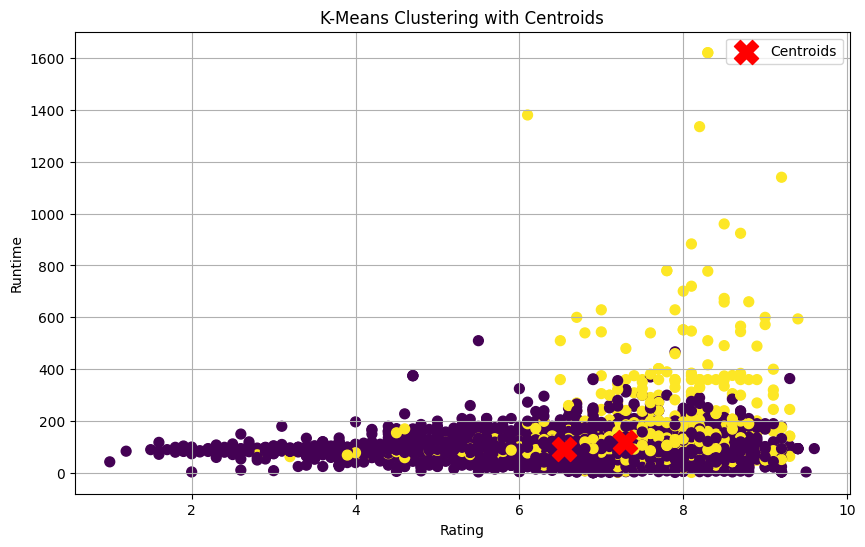

In [ ]:
plt.figure(figsize=(10,6))

plt.scatter(
    df['rating'],
    df['runtime'],
    c=df['Cluster'],
    s=50
)

plt.scatter(
    centroid_df['rating'],
    centroid_df['runtime'],
    marker='X',
    s=300,
    c='red',
    label='Centroids'
)

plt.xlabel("Rating")
plt.ylabel("Runtime")

plt.title(
    "K-Means Clustering with Centroids"
)

plt.legend()
plt.grid()

plt.show()

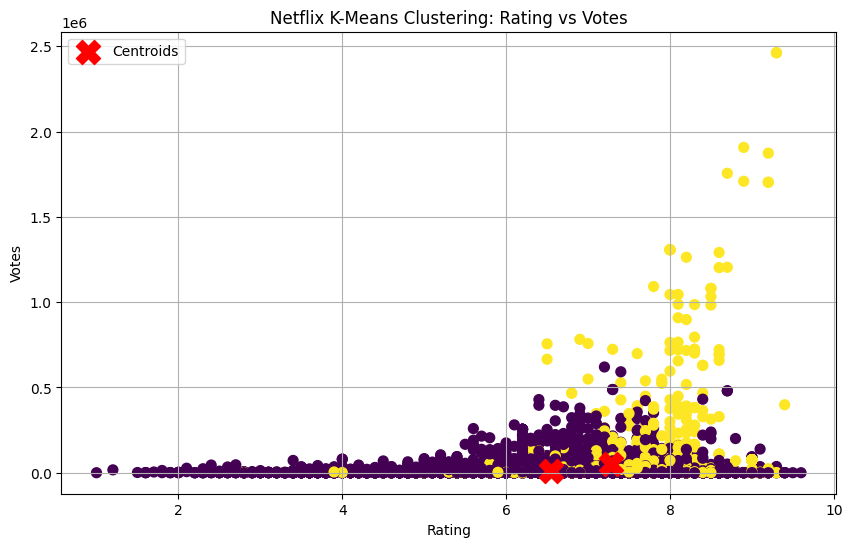

In [ ]:
plt.figure(figsize=(10,6))

plt.scatter(
    df['rating'],
    df['vote'],
    c=df['Cluster'],
    s=50
)

# Centroids

plt.scatter(
    centroid_df['rating'],
    centroid_df['vote'],
    marker='X',
    s=300,
    color='red',
    label='Centroids'
)

plt.xlabel("Rating")
plt.ylabel("Votes")

plt.title(
    "Netflix K-Means Clustering: Rating vs Votes"
)

plt.legend()
plt.grid()

plt.show()

In [ ]:
df['content'] = df['genre'].fillna('')

tfidf = TfidfVectorizer(stop_words='english')

tfidf_matrix = tfidf.fit_transform(df['content'])

content_similarity = cosine_similarity(tfidf_matrix)

content_sim_df = pd.DataFrame(
    content_similarity,
    index=df['title'],
    columns=df['title']
)

In [ ]:
ratings = df[['title', 'rating']].copy()
ratings['user_id'] = 1
user_item_matrix = ratings.pivot_table(
    index='user_id',
    columns='title',
    values='rating',
    aggfunc='mean'
).fillna(0)

print("Rating Matrix:")
print(user_item_matrix.head())

Rating Matrix:
title    "Curb Your Enthusiasm" Season 10 Highlights  \
user_id                                                
1                                                7.2   

title    "The Fosters" Season 5 Set Visit  \
user_id                                     
1                                     6.9   

title    $ellebrity: The Go-To Girls - A Special Edition of 20/20  \
user_id                                                             
1                                                      6.9          

title    'Angel': Season 4 Overview  'Angel': Season One  \
user_id                                                    
1                               6.7                  8.4   

title    'Manos' the Hands of Fate  'N Sync: 'N the Mix  \
user_id                                                   
1                              9.1                  7.8   

title    'N Sync: Making the Tour  'N Sync: PopOdyssey Live  'R Xmas  ...  \
user_id                             

In [ ]:
user_similarity = cosine_similarity(user_item_matrix)

user_similarity_df = pd.DataFrame(
    user_similarity,
    index=user_item_matrix.index,
    columns=user_item_matrix.index
)

In [ ]:
def hybrid_recommendation(
    user_id,
    movie_title,
    n=10,
    content_weight=0.5,
    collaborative_weight=0.5
):

    if movie_title not in content_sim_df.index:
        print(f"Movie '{movie_title}' not found in content similarity matrix!")
        return None

    if user_id not in user_item_matrix.index:
        print(f"User ID '{user_id}' not found in user-item matrix!")
        return None

    content_scores = content_sim_df[movie_title].sort_values(
        ascending=False
    )

    similar_users = user_similarity_df[user_id].sort_values(
        ascending=False
    )

    collab_scores = pd.Series(0.0, index=content_sim_df.index)

    for other_user, similarity in similar_users.items():
        if other_user == user_id:
            continue

        if other_user not in user_item_matrix.index:
            continue

        other_user_ratings = user_item_matrix.loc[other_user]

        for movie_rated_by_other, rating_value in other_user_ratings.items():
            if rating_value > 0:
                if movie_rated_by_other in collab_scores.index:
                    collab_scores[movie_rated_by_other] += similarity * rating_value

    if collab_scores.max() > 0:
        collab_scores = (
            collab_scores / collab_scores.max()
        )
    else:
        print("Warning: Collaborative scores are all zero.")

    hybrid_score = (
        content_weight * content_scores +
        collaborative_weight * collab_scores
    )
    hybrid_score = hybrid_score.drop(
        movie_title,
        errors='ignore'
    )

    result = hybrid_score.sort_values(
        ascending=False
    ).head(n)

    result = pd.DataFrame({
        'title': result.index,
        'hybrid_score': result.values
    })

    return result

In [ ]:
recommendations = hybrid_recommendation(
    user_id=1,
    movie_title="Predator",
    n=10
)

if recommendations is not None:
    print(recommendations)
else:
    print("No recommendations generated.")

                                    title  hybrid_score
0  Star Trek VI: The Undiscovered Country      0.500000
1               They Saved Hitler's Brain      0.500000
2                               Mad Max 2      0.500000
3                                 Mad Max      0.500000
4                   Descent Into Darkness      0.500000
5                  The Day After Tomorrow      0.500000
6                           Jurassic Park      0.500000
7                      Planet of the Apes      0.500000
8               Godzilla 2000: Millennium      0.482141
9                                    10.5      0.482141


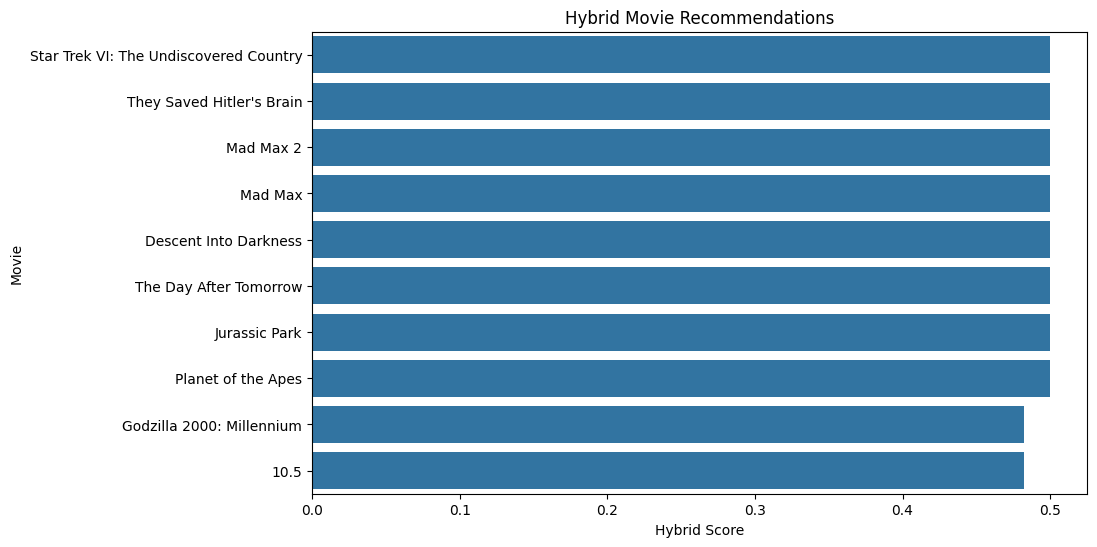

In [ ]:
if recommendations is not None:
    plt.figure(figsize=(10, 6))

    sns.barplot(
        data=recommendations,
        x='hybrid_score',
        y='title'
    )

    plt.title("Hybrid Movie Recommendations")
    plt.xlabel("Hybrid Score")
    plt.ylabel("Movie")

    plt.show()
else:
    print("Cannot plot recommendations: No recommendations were generated.")